# Palmer Penguins: Morphological Differences Across Species

**Research question:** How do body measurements (bill length, bill depth, flipper length, body mass) differ across the three penguin species (Adelie, Chinstrap, Gentoo), and can these features distinguish species?

**Dataset:** Palmer Penguins, loaded via `seaborn.load_dataset("penguins")`. Original data from Palmer Station Antarctica LTER, license CC0 (public domain).

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Global plot style
sns.set_theme(style="whitegrid")

# Make sure the images folder exists
os.makedirs("images", exist_ok=True)

# Load the dataset
df = sns.load_dataset("penguins")
print("Shape:", df.shape)
df.head()

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [2]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [3]:
# Drop rows with missing values for a clean analysis
df_clean = df.dropna().copy()
print("Original rows:", len(df))
print("Rows after dropping missing values:", len(df_clean))
print("Species counts:")
print(df_clean["species"].value_counts())

Original rows: 344
Rows after dropping missing values: 333
Species counts:
species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64


In [4]:
# Summary statistics by species
summary = (
    df_clean.groupby("species")[["bill_length_mm", "bill_depth_mm",
                                 "flipper_length_mm", "body_mass_g"]]
    .mean()
    .round(2)
)
summary

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.82,18.35,190.10,3706.16
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.57,15.00,217.24,5092.44


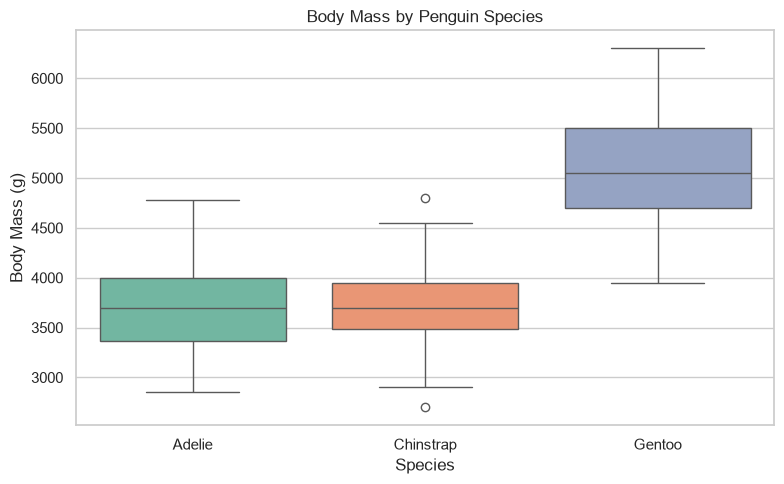

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    palette="Set2",
    legend=False,
)
plt.title("Body Mass by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")
plt.tight_layout()
plt.savefig("images/fig1_boxplot.png", dpi=150)
plt.show()

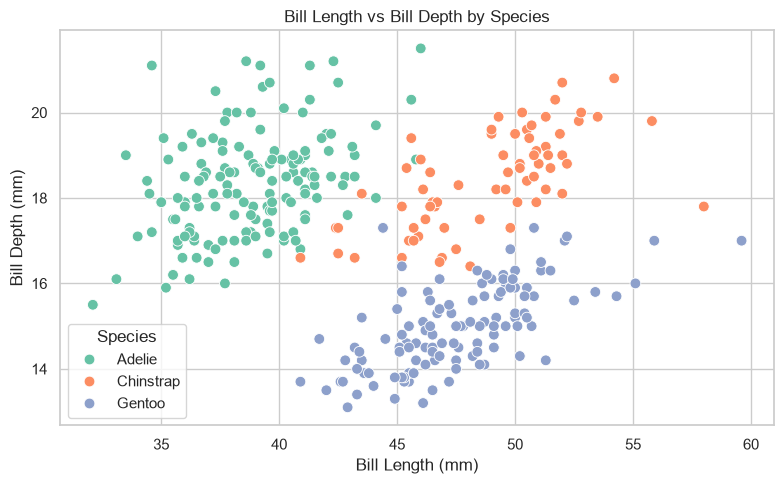

In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    palette="Set2",
    s=60,
)
plt.title("Bill Length vs Bill Depth by Species")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.legend(title="Species")
plt.tight_layout()
plt.savefig("images/fig2_scatter.png", dpi=150)
plt.show()

## Key Findings

1. **Body mass differs strongly by species.** Gentoo penguins have clearly larger body mass than Adelie and Chinstrap penguins (see `images/fig1_boxplot.png`).
2. **Bill length and bill depth separate the species.** In the scatter plot (`images/fig2_scatter.png`), the three species form fairly distinct clusters, suggesting these two features are useful for species discrimination.

## Limitation

The dataset contains only three species from a single region (Palmer Archipelago) and has missing values that were removed. Results may not generalize to other penguin populations.

In [7]:
print(os.listdir("images"))

['fig1_boxplot.png', 'fig2_scatter.png']
